# BERT Sentiment Fine-Tuning

Fine-tune a BERT-family sequence classifier using Hugging Face Transformers. It requires internet access to download the pretrained model and enough RAM/CPU/GPU. Start with a smaller sample if your machine is resource-limited.

In [5]:
!git clone https://github.com/LUCIUSNJOKU/MONTRA_HOSPITALITY_PJ.git
%cd MONTRA_HOSPITALITY_PJ

Cloning into 'MONTRA_HOSPITALITY_PJ'...
remote: Enumerating objects: 37642, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 37642 (delta 1), reused 15 (delta 1), pack-reused 37624 (from 1)
Receiving objects: 100% (37642/37642), 298.41 MiB | 17.55 MiB/s, done.
Resolving deltas: 100% (5714/5714), done.
/content/MONTRA_HOSPITALITY_PJ


## Install dependencies

In [3]:
!pip install transformers datasets accelerate evaluate scikit-learn torch

In [4]:
# Import all Libraries
from IPython.core.debugger import Pdb
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import joblib
from datasets import Dataset
from transformers import AutoTokenizer
import evaluate
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, TrainingArguments,
    Trainer, DataCollatorWithPadding)
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
    accuracy_score, f1_score, precision_recall_fscore_support)

In [8]:
# Load cleaned Dataset
from google.colab import files
uploaded = files.upload()

Saving cleaned_montra_data.csv to cleaned_montra_data.csv


In [9]:
# Create the working directory fro the dataset
DATA_DIR = Path("../Dataset/proceesed_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Directory Created:", DATA_DIR.resolve())


# Read the dataset
cleaned_data = pd.read_csv("cleaned_montra_data.csv")
cleaned_data.head()

Directory Created: /content/Dataset/proceesed_data


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,country,previous_stays,hotel_name,location,star_rating,total_rooms,light_text,heavy_text,n_words,label
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,Suite,Direct Website,...,France,4,The Aberdeen Grand,Aberdeen,4,118,The overall price was fair for what we paid. M...,overall price fair paid consider not,15,positive
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,...,Germany,4,Nottingham Park Hotel,Nottingham,4,95,The room was nothing out of the ordinary for w...,room ordinary paid overall price exceeded expe...,28,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,Executive,Travel Agent,...,Ireland,4,The London Boutique,London,4,231,"Unfortunately, the pool was outdated it clear...",unfortunately pool outdated clearly needed upk...,15,negative
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,Family Room,Airbnb,...,Nigeria,0,Manchester Metropolitan,Manchester,3,101,We were disappointed that the neighborhood was...,disappointed neighborhood disappointingly way ...,21,positive
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,Deluxe,Expedia,...,United States,9,Glasgow Metropolitan,Glasgow,4,214,The room service was standard hotel fare for w...,room service standard hotel fare paid said bed...,39,positive


In [10]:
## Extracting the Review as a Document
doc =(cleaned_data['heavy_text'].astype(str).tolist())
print(f"Total Document:{len(doc)}")
doc[:10]

Total Document:35000


['overall price fair paid consider not',
 'room ordinary paid overall price exceeded expectation great deal quality easily matched price',
 'unfortunately pool outdated clearly needed upkeep wouldn recommend',
 'disappointed neighborhood disappointingly way sadly room turned grimy',
 'room service standard hotel fare paid said bedding decent shape paid cost stay reasonable paid',
 'getting hotel unsafe area really affected stay said check process delayed clear reason really affected stay',
 'couldn asked better base visiting london plus overall restaurant write home expected genuinely impressed arrival experience seamless genuinely great',
 'wonderful time stay nottingham plus surrounding area exceeded expectation ideally situated restaurant shop nearby',
 'house cafe acceptable paid said gym basic but functional paid',
 'manager fine special paid fitness facility special did job surprise']

In [11]:
# Define the sentiment labels
LABELS = ["negative", "neutral", "positive"]

# label ID`s
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {0: "negative", 1: "neutral", 2: "positive"}

# Standardise the sentiment labels
cleaned_data["sentiment_label"] = (cleaned_data["sentiment_label"].astype(str)
                                   .str.lower().str.strip())

# Remove missing text, empty reviews and invalid labels
cleaned_data = cleaned_data[cleaned_data["heavy_text"].notna()
    & cleaned_data["heavy_text"].astype(str).str.strip().ne("")
    & cleaned_data["sentiment_label"].isin(LABELS)].copy()

# checks before splitting
print("Rows after filtering:", len(cleaned_data))
print(cleaned_data["sentiment_label"].value_counts())
print("-"*40)

# Convert sentiment labels to numbers
cleaned_data["label"] = cleaned_data["sentiment_label"].map(label2id)

# Split into training (60%) and temporary data (40%)
train_data, temp_data = train_test_split(cleaned_data,test_size=0.40,
                                     random_state=42,
                                         stratify=cleaned_data["label"])

# Split temporary data equally into validation and test sets
valid_data, test_data = train_test_split(temp_data, test_size=0.50,
    random_state=42, stratify=temp_data["label"])

# Display dataset sizes
print("Training data:", len(train_data))
print("Validation data:", len(valid_data))
print("Test data:", len(test_data))

# Check sentiment distribution in each dataset
for name, data in [("Training", train_data), ("Validation", valid_data),
    ("Test", test_data)]:

    print(f"\n{name} sentiment distribution:")
    print("-"*40)
    print(data["sentiment_label"].value_counts())


Rows after filtering: 35000
sentiment_label
neutral     13355
positive    11782
negative     9863
Name: count, dtype: int64
----------------------------------------
Training data: 21000
Validation data: 7000
Test data: 7000

Training sentiment distribution:
----------------------------------------
sentiment_label
neutral     8013
positive    7069
negative    5918
Name: count, dtype: int64

Validation sentiment distribution:
----------------------------------------
sentiment_label
neutral     2671
positive    2356
negative    1973
Name: count, dtype: int64

Test sentiment distribution:
----------------------------------------
sentiment_label
neutral     2671
positive    2357
negative    1972
Name: count, dtype: int64


# Tokenise Review Text

In [12]:
# Set the BERT model and maximum review length
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Check that the datasets contain reviews and labels
for name, frame in [("Training", train_data),("Validation", valid_data),
    ("Test", test_data)]:
    print(f"{name} rows: {len(frame)}")

    # condition for tokenizing
    if frame.empty:
        raise ValueError(f"{name} dataset is empty.")

    if frame["heavy_text"].isna().any():
        raise ValueError(f"{name} contains missing review text.")

    if frame["label"].isna().any():
        raise ValueError(f"{name} contains missing labels.")

# Convert pandas DataFrames to Hugging Face datasets
def to_hf_dataset(hug_frame):
    dataset = Dataset.from_pandas(
        hug_frame[["heavy_text", "label"]].rename(
            columns={"heavy_text": "text"}
        ),
        preserve_index=False
    )

    return dataset

train_ds = to_hf_dataset(train_data)
valid_ds = to_hf_dataset(valid_data)
test_ds = to_hf_dataset(test_data)

# Apply Tokenize to the review text
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )

train_ds = train_ds.map(tokenize_batch, batched=True)
valid_ds = valid_ds.map(tokenize_batch, batched=True)
test_ds = test_ds.map(tokenize_batch, batched=True)

# Select the columns needed for BERT
columns = ["input_ids", "attention_mask", "label"]

if "token_type_ids" in train_ds.column_names:
    columns.append("token_type_ids")

# Convert the datasets to PyTorch tensors
train_ds.set_format(type="torch", columns=columns)
valid_ds.set_format(type="torch", columns=columns)
test_ds.set_format(type="torch", columns=columns)

# Confirm the preparation is complete
print("\nBERT datasets prepared successfully.")
print("Training:", len(train_ds))
print("Validation:", len(valid_ds))
print("Testing:", len(test_ds))

print("\nExample tokenised review:")
print(train_ds[0])


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Training rows: 21000
Validation rows: 7000
Test rows: 7000


Map:   0%|          | 0/21000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7000 [00:00<?, ? examples/s]


BERT datasets prepared successfully.
Training: 21000
Validation: 7000
Testing: 7000

Example tokenised review:
{'label': tensor(1), 'input_ids': tensor([ 101, 3452, 5887, 2953, 6623, 2768, 2126,  102,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0

# BERT_FINE-TUNNING

In [13]:
# Load the pre-trained BERT model
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,
    num_labels=len(LABELS), label2id=label2id, id2label=id2label)

# Calculate evaluation metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Get predicted sentiment IDs
    predictions = np.argmax(logits, axis=-1)

    # Calculate macro precision, recall and F1
    precision, recall, f1, _ = precision_recall_fscore_support(labels,
        predictions, labels=[0, 1, 2], average="macro",
        zero_division=0)

    return {"accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1,
        "macro_precision": precision,
        "macro_recall": recall}

# Set training parameters
training_args = TrainingArguments(output_dir="../Model/bert_checkpoints",
    learning_rate=2e-5, per_device_train_batch_size=8,
    per_device_eval_batch_size=8, num_train_epochs=3,
    weight_decay=0.01, eval_strategy="epoch",
    save_strategy="epoch", load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1", greater_is_better=True,
    logging_steps=50, report_to="none", seed=42)

# Create the data collator
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Create the Trainer
trainer = Trainer(model=model, args=training_args, train_dataset=train_ds,
    eval_dataset=valid_ds, processing_class=tokenizer,
    data_collator=data_collator, compute_metrics=compute_metrics)

# Fine-tune BERT
trainer.train()


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.306935,0.276661,0.943286,0.944691,0.946402,0.943390
2,0.342838,0.257776,0.943286,0.944691,0.946402,0.943390
3,0.291358,0.266973,0.943429,0.944838,0.946577,0.943514


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=7875, training_loss=0.2806161578950428, metrics={'train_runtime': 3372.0284, 'train_samples_per_second': 18.683, 'train_steps_per_second': 2.335, 'total_flos': 8288072658432000.0, 'train_loss': 0.2806161578950428, 'epoch': 3.0})

# BERT Model Evaluation

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Macro Precision,Macro Recall
0.291358,0.286862,3,0.938571,0.940050,0.943299,0.937628


BERT Test Metrics:


{'test_loss': 0.2868618369102478,
 'test_accuracy': 0.9385714285714286,
 'test_macro_f1': 0.9400495547234736,
 'test_macro_precision': 0.9432988812855889,
 'test_macro_recall': 0.937628376401667}


BERT Classification Report:
              precision    recall  f1-score   support

    negative     0.9662    0.9280    0.9467      1972
     neutral     0.8978    0.9468    0.9216      2671
    positive     0.9659    0.9381    0.9518      2357

    accuracy                         0.9386      7000
   macro avg     0.9433    0.9376    0.9400      7000
weighted avg     0.9400    0.9386    0.9389      7000



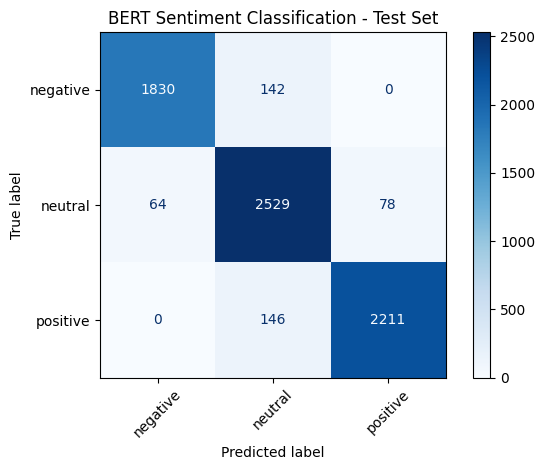

In [18]:
# Evaluate BERT on the test dataset
test_metrics = trainer.evaluate(eval_dataset=test_ds,
    metric_key_prefix="test")

print("BERT Test Metrics:")
display(test_metrics)

# Generate predictions
test_output = trainer.predict(test_ds)

test_pred_ids = np.argmax(test_output.predictions,axis=1)

# Convert numeric predictions to sentiment labels
test_pred_labels = [id2label[int(i)] for i in test_pred_ids]

# Actual sentiment labels
test_true_labels = test_data["sentiment_label"].tolist()

# Display classification report
print("\nBERT Classification Report:")

print(classification_report(test_true_labels, test_pred_labels,
    labels=LABELS, target_names=LABELS, digits=4,
    zero_division=0))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(test_true_labels,
    test_pred_labels, labels=LABELS, display_labels=LABELS,
    cmap="Blues", xticks_rotation=45, values_format="d")

plt.title("BERT Sentiment Classification - Test Set")
plt.tight_layout()
plt.show()




# Save Model, Tokenizer & Model Predictions


In [5]:
OUT = Path("../Model/bert_sentiment")
OUT.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(OUT))
tokenizer.save_pretrained(str(OUT))

bert_predictions = test_data.copy()
bert_predictions["predicted_sentiment"] = test_pred_labels
bert_predictions.to_csv(
    "../Dataset/modelled_data/bert_test_predictions.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(
    "../Results/reports_bert_test_metrics.csv", index=False)
print("Saved BERT model, tokenizer and predictions.")

NameError: name 'trainer' is not defined